# PM-07-PS03 Beginner Tutorial: Statistical Techniques

Welcome. This notebook uses a cleaned CityConnect dataset. The goal is to **describe the numbers**, **interpret deviations**, and try the main analysis techniques from this module.

You do **not** need to know every technique before starting. Each section has a short explanation, example code, then a written answer.

## What you will do

- PA0301 to PA0305: mean, standard deviation, residual spread, range, IQR and skewness
- PA0306: a beginner version of regression, Monte Carlo, factor analysis, cohort analysis, cluster analysis, time series and sentiment analysis

## Important rules

- Do not manually edit `cityconnect_resolved_requests.csv`.
- Every calculated answer must come from Python.
- Write interpretations in your own words. A number without a sentence is not complete.


# Step 0 — Set up Python


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_FOLDER = Path(".")
OUTPUTS = DATA_FOLDER / "outputs"
OUTPUTS.mkdir(exist_ok=True)
rng = np.random.default_rng(13)

requests = pd.read_csv(DATA_FOLDER / "cityconnect_resolved_requests.csv")
requests["opened_on"] = pd.to_datetime(requests["opened_on"])
requests["closed_on"] = pd.to_datetime(requests["closed_on"])
days = requests["resolution_days"]

print("Rows:", len(requests))
display(requests.head())


Rows: 420


,request_id,opened_on,closed_on,service_type,region,priority,resolution_days,satisfaction_rating,travel_minutes,resident_comment
0,SR00001,2026-03-13,2026-03-26,Water,South,Medium,12.9,2,38,Angry about the wait. Nobody explained the delay.
1,SR00002,2026-02-09,2026-02-14,Water,CBD,High,4.7,4,12,Work completed as logged.
2,SR00003,2026-05-25,2026-05-28,Water,South,Low,2.5,5,38,Team arrived quickly and fixed the issue. Than...
3,SR00004,2026-03-03,2026-03-19,Sanitation,West,Medium,15.6,2,34,Poor communication and slow repair. Not resolv...
4,SR00005,2026-05-08,2026-05-10,Waste,West,High,1.3,5,34,"Happy with the repair, well done CityConnect."


# PA0301 — Mean and standard deviation

- **Mean** is the average resolution time.
- **Standard deviation (SD)** is the typical distance from that average. A large SD means waiting times are inconsistent.

If two groups have a similar mean but one has a much larger SD, residents in that group have a less predictable experience.


In [2]:
print("Mean resolution days:", round(days.mean(), 2))
print("Standard deviation:", round(days.std(), 2))
print()
by_service = (
    requests.groupby("service_type")["resolution_days"]
    .agg(count="count", mean="mean", std="std")
    .round(2)
    .sort_values("mean")
)
display(by_service)


Mean resolution days: 9.18
Standard deviation: 9.44



,count,mean,std
service_type,,,
Waste,65,4.12,3.24
Sanitation,61,4.86,3.11
Electricity,98,7.90,6.12
Roads,76,9.93,7.15
Water,120,14.67,13.60


## Your written answer for PA0301

- Overall mean and SD:
- Which service type has the most inconsistent waiting time?
- What would you tell operations in one sentence?

1. Overall mean and standard deviation - On average, CityConnect takes 9.18 days to resolve a service request. The standard deviation of 9.44 days indicates considerable variation in resolution times.
  - Mean: 9.18 days
  - Standard deviation: 9.44 days

2. Which service type has the most inconsistent waiting time? - Water.
Water services have the highest standard deviation of 13.60 days, meaning their resolution times vary more than those of other service types. Some requests are resolved quickly, while others take significantly longer.

3. What would you tell operations in one sentence? - CityConnect operations should prioritise improving water service resolution times because Water has the longest average waiting time (14.67 days) and the highest variation (13.60 days), indicating inconsistent service delivery.


# PA0302 — Interpret the standard deviation of residuals

A **residual** is actual minus predicted:

`residual = actual resolution_days − predicted resolution_days`

The **SD of residuals** says how far typical requests still sit from the model. If this SD is almost as large as the original SD, the model is not explaining much.


Original SD of resolution days: 9.44
SD of residuals: 8.26
Mean residual (should be close to 0): 0.0


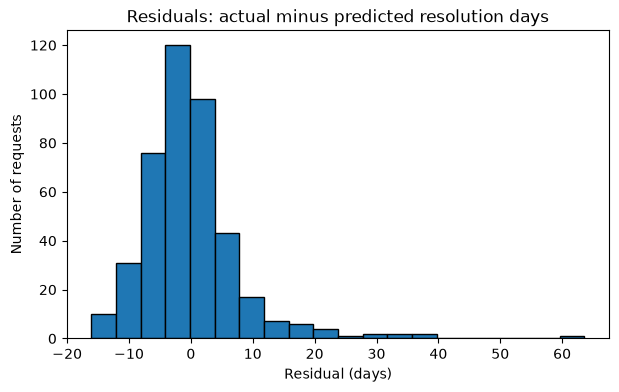

In [3]:
feature_frame = pd.get_dummies(requests[["service_type", "region", "priority"]], drop_first=True)
feature_cols = list(feature_frame.columns)
X = np.column_stack([np.ones(len(feature_frame)), feature_frame.to_numpy()])
y = days.to_numpy()
coeffs, *_ = np.linalg.lstsq(X, y, rcond=None)
requests["predicted_days"] = X @ coeffs
requests["residual"] = requests["resolution_days"] - requests["predicted_days"]

print("Original SD of resolution days:", round(days.std(), 2))
print("SD of residuals:", round(requests["residual"].std(), 2))
print("Mean residual (should be close to 0):", round(requests["residual"].mean(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(requests["residual"], bins=20, edgecolor="black")
ax.set_title("Residuals: actual minus predicted resolution days")
ax.set_xlabel("Residual (days)")
ax.set_ylabel("Number of requests")
plt.show()


## Your written answer for PA0302

- SD of residuals:
- Is it much smaller than the original SD, or only a little smaller?
- What does that say about this first model?

1. SD of residuals - 8.26 days

2. Is it much smaller than the original SD, or only a little smaller? - It is only a little smaller. The original standard deviation is 9.44 days, while the residual standard deviation is 8.26 days.

3. What does that say about this first model? - he first model explains only a small portion of the variation in resolution times. Although it improves the predictions slightly, there is still considerable unexplained variation, meaning other factors influence how long service requests take to resolve.


# PA0303 — Interpret the range

**Range** = maximum − minimum.

It is easy to calculate, but one extreme delay can make the range huge. Use it to spot extremes, not as your only spread measure.


In [4]:
print("Minimum:", days.min())
print("Maximum:", days.max())
print("Range:", round(days.max() - days.min(), 2))
print("Longest request ID:")
display(requests.loc[days.idxmax(), ["request_id", "service_type", "region", "priority", "resolution_days", "resident_comment"]])


Minimum: 0.4
Maximum: 82.2
Range: 81.8
Longest request ID:


request_id                                                    SR00132
service_type                                                    Water
region                                                          South
priority                                                          Low
resolution_days                                                  82.2
resident_comment    Angry about the wait. Nobody explained the delay.
Name: 131, dtype: object

## Your written answer for PA0303

- Range:
- What kind of request created the maximum?
- Why is range a risky summary for management?

1. Range - 81.8 days (82.2 − 0.4).

2. What kind of request created the maximum? - A Water service request from the South region, with Low priority, took 82.2 days to resolve. The resident was unhappy about the delay and lack of communication.

3. Why is range a risky summary for management? - Range is risky because it only considers the minimum and maximum values and ignores how the rest of the requests are distributed. One unusually long request can make the range appear extremely high, potentially giving management a misleading picture of overall performance.


# PA0304 — Interpret the interquartile range

**IQR** = 75th percentile − 25th percentile. It is the width of the middle 50% of requests.

IQR ignores the most extreme delays, so it is usually a fairer “typical spread” than range.


Q1: 3.5
Q3: 11.6
IQR: 8.1
Range: 81.8


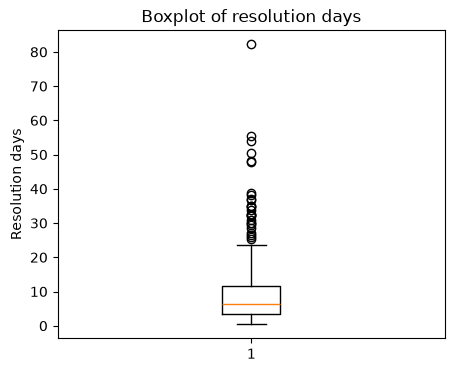

In [6]:
q1 = days.quantile(0.25)
q3 = days.quantile(0.75)

print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(q3 - q1, 2))
print("Range:", round(days.max() - days.min(), 2))

fig, ax = plt.subplots(figsize=(5, 4))

ax.boxplot(days, orientation="vertical")

ax.set_title("Boxplot of resolution days")
ax.set_ylabel("Resolution days")

plt.show()


## Your written answer for PA0304

- IQR:
- How much smaller is IQR than the range?
- Which measure would you put on an operations dashboard, and why?

1. IQR - 8.1 days (11.6 − 3.5).

2. How much smaller is IQR than the range? - The IQR is 73.7 days smaller than the range (81.8 − 8.1).

3. Which measure would you put on an operations dashboard, and why? - I would use the IQR because it shows the spread of the middle 50% of service resolution times and is less affected by extreme delays or outliers. This gives management a more reliable picture of typical operational performance.


# PA0305 — Interpret skewness

**Right-skewed (positive):** a long tail of slow jobs. Mean is pulled above the median.

City service data is often right-skewed: most jobs finish in a few days, and a smaller number drag on.


Mean: 9.18
Median: 6.5
Skewness: 2.93


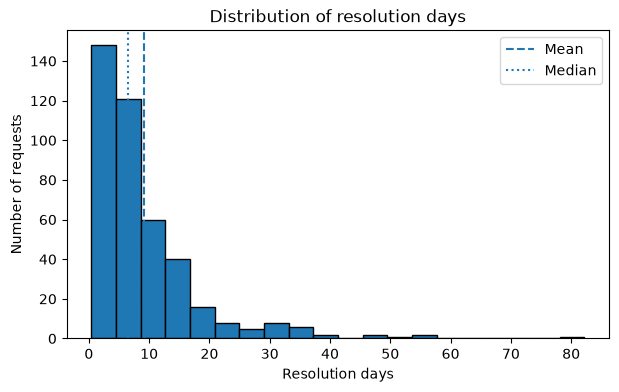

In [7]:
print("Mean:", round(days.mean(), 2))
print("Median:", round(days.median(), 2))
print("Skewness:", round(days.skew(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(days, bins=20, edgecolor="black")
ax.axvline(days.mean(), linestyle="--", label="Mean")
ax.axvline(days.median(), linestyle=":", label="Median")
ax.set_title("Distribution of resolution days")
ax.set_xlabel("Resolution days")
ax.set_ylabel("Number of requests")
ax.legend()
plt.show()


## Your written answer for PA0305

- Is the distribution left-skewed, right-skewed or roughly symmetric?
- How do the mean, median and histogram support that?
- What does the long tail mean for residents?

1. Is the distribution left-skewed, right-skewed or roughly symmetric? - The distribution is right-skewed (positively skewed) because the skewness value is 2.93, which indicates a long tail towards higher resolution times.

2. How do the mean, median and histogram support that? - The mean is 9.18 days, which is higher than the median of 6.5 days. This suggests that a few requests with very long resolution times are pulling the average upwards. The histogram should show most requests clustered around shorter resolution times, with a long tail extending towards higher values.

3. What does the long tail mean for residents? - The long tail means that while many residents receive relatively quick service, some experience extremely long delays before their requests are resolved. This can lead to frustration, dissatisfaction and reduced trust in CityConnect's service delivery.


# PA0306 — Seven analysis techniques

The rest of the notebook is a **beginner pass** through each technique. You are not expected to produce a research paper. You are expected to run the method, read the output, and say what it means for CityConnect.


## 1. Regression analysis

We already fitted a linear model. Regression asks: which inputs help estimate resolution time?

Look at the coefficients. A positive coefficient means that group is slower than the baseline group after the other variables are considered.


In [8]:
coef_table = pd.DataFrame({
    "term": ["intercept"] + feature_cols,
    "coefficient": coeffs.round(2),
}).sort_values("coefficient", ascending=False)
coef_table.to_csv(OUTPUTS / "regression_coefficients.csv", index=False)
display(coef_table.head(8))
print("SD of residuals:", round(requests["residual"].std(), 2))


,term,coefficient
4,service_type_Water,6.63
7,region_South,5.29
8,region_West,4.21
9,priority_Low,3.48
5,region_East,3.30
0,intercept,3.19
1,service_type_Roads,2.26
6,region_North,1.40


SD of residuals: 8.26


## Your written answer — regression

- Which term has the largest positive coefficient (slower)?
- Which term has the largest negative coefficient (faster)?
- Would you use this regression to staff teams yet? Why or why not?

1. Which term has the largest positive coefficient (slower)? - service_type_Water = +6.63
This indicates that Water service requests are associated with longer resolution times compared with the reference service category, holding other model variables constant.

2. Which term has the largest negative coefficient (faster)? - The table provided only shows positive coefficients. Therefore, the largest negative coefficient cannot be identified from the displayed results. You would need to check the full regression coefficients for negative values.

3. Would you use this regression to staff teams yet? Why or why not? - No, I would not use this regression model for staffing decisions yet.


The model has a residual standard deviation of 8.26 days, meaning its predictions still have considerable errors. I would first improve the model by including additional factors such as workload, request complexity, team availability and resource allocation before using it to make staffing decisions.


## 2. Monte Carlo simulation

Monte Carlo means: **repeat a random process many times** to estimate a probability.

Here we resample the observed resolution times 5,000 times. That estimates the chance a random completed request takes more than 14 days, without assuming a perfect bell curve.


Monte Carlo P(resolution_days > 14): 0.169
That is about 17 in 100 completed requests.


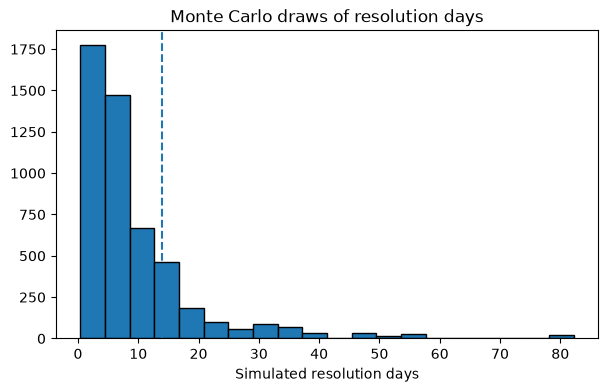

In [9]:
n_sims = 5000
simulated = rng.choice(days.to_numpy(), size=n_sims, replace=True)
prob_over_14 = (simulated > 14).mean()
print("Monte Carlo P(resolution_days > 14):", round(prob_over_14, 3))
print("That is about", int(round(prob_over_14 * 100)), "in 100 completed requests.")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(simulated, bins=20, edgecolor="black")
ax.axvline(14, linestyle="--")
ax.set_title("Monte Carlo draws of resolution days")
ax.set_xlabel("Simulated resolution days")
plt.show()


## Your written answer — Monte Carlo

- Estimated probability a job takes more than 14 days:
- Why is resampling useful when the data is skewed?
- One operations decision this probability could support:

1. Estimated probability a job takes more than 14 days - 16.9% (approximately 17 in every 100 requests). This means that roughly 17 out of every 100 service requests may take longer than 14 days to resolve.

2. Why is resampling useful when the data is skewed? - Resampling is useful because it uses the actual distribution of the data, including unusually long resolution times. It does not assume that resolution times follow a normal distribution, making the estimates more realistic.

3. One operations decision this probability could support: - Management could use this probability to improve resource allocation and prioritise delayed requests, particularly in the Water department, to reduce the number of residents waiting longer than 14 days.


## 3. Factor analysis (beginner version)

Full factor analysis looks for hidden factors behind many variables. A beginner first step is the **correlation matrix**: which numeric variables move together?

- Correlation near **+1**: they rise together.
- Correlation near **−1**: one rises while the other falls.
- Correlation near **0**: little linear relationship.


,resolution_days,satisfaction_rating,travel_minutes,priority_score
resolution_days,1.00,-0.59,0.22,-0.13
satisfaction_rating,-0.59,1.00,-0.15,0.05
travel_minutes,0.22,-0.15,1.00,-0.02
priority_score,-0.13,0.05,-0.02,1.00


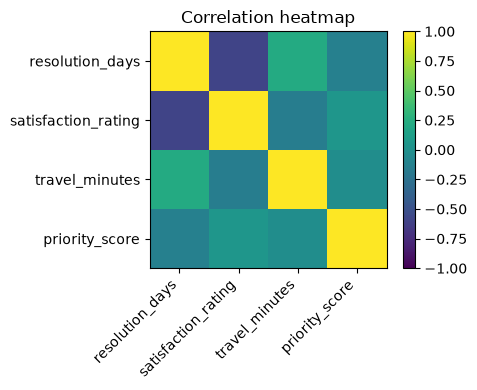

In [10]:
priority_score = requests["priority"].map({"Low": 1, "Medium": 2, "High": 3})
factor_data = pd.DataFrame({
    "resolution_days": requests["resolution_days"],
    "satisfaction_rating": requests["satisfaction_rating"],
    "travel_minutes": requests["travel_minutes"],
    "priority_score": priority_score,
})
corr = factor_data.corr().round(2)
corr.to_csv(OUTPUTS / "correlation_matrix.csv")
display(corr)

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
fig.colorbar(image, ax=ax)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.show()


## Your written answer — factor analysis

- Which pair of variables has the strongest relationship?
- Does longer travel go with slower resolution?
- Does higher satisfaction go with shorter resolution?

1. Which pair of variables has the strongest relationship? - Resolution days and satisfaction rating (-0.59). They have the strongest relationship because they have the largest absolute correlation value. The negative correlation indicates that as resolution time increases, satisfaction tends to decrease.

2. Does longer travel go with slower resolution?- Yes, to some extent. Travel minutes and resolution days have a positive correlation of 0.22. This suggests that longer travel times are slightly associated with longer resolution times, although the relationship is weak.

3. Does higher satisfaction go with shorter resolution? - Yes. There is a negative correlation of -0.59 between satisfaction rating and resolution days. This suggests that residents tend to give higher satisfaction ratings when their service requests are resolved more quickly.

## 4. Cohort analysis

A **cohort** is a group that started in the same period. Here, the cohort is the **month the request was opened**.

We check whether later months are faster or slower than earlier months.


,count,mean,median
opened_month,,,
2026-01,59,10.39,7.00
2026-02,62,8.76,4.85
2026-03,86,8.67,5.95
2026-04,79,10.56,8.00
2026-05,72,8.00,6.60
2026-06,62,8.75,5.70


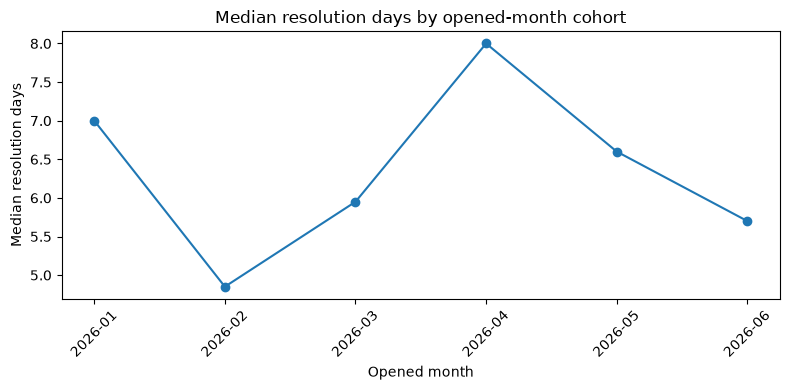

In [11]:
requests["opened_month"] = requests["opened_on"].dt.to_period("M").astype(str)
cohort = (
    requests.groupby("opened_month")["resolution_days"]
    .agg(count="count", mean="mean", median="median")
    .round(2)
)
cohort.to_csv(OUTPUTS / "cohort_by_opened_month.csv")
display(cohort)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cohort.index, cohort["median"], marker="o")
ax.set_title("Median resolution days by opened-month cohort")
ax.set_xlabel("Opened month")
ax.set_ylabel("Median resolution days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Your written answer — cohort analysis

- Which month-cohort looks slowest?
- Is the pattern getting better, worse, or mixed?
- Why is a cohort view more useful than one overall average?

1. Which month-cohort looks slowest? - April 2026, with an average resolution time of 10.56 days and a median of 8.00 days. January is the second slowest, with an average of 10.39 days.

2. Is the pattern getting better, worse, or mixed? - The pattern is mixed. Resolution times improved from January to March, increased again in April, improved in May, and increased slightly in June. This suggests that service delivery performance is not consistently improving.

3. Why is a cohort view more useful than one overall average? - A cohort view allows management to compare service performance across different months and identify periods when resolution times increase or decrease. It helps identify operational problems and seasonal patterns that an overall average might hide.

## 5. Cluster analysis

Cluster analysis groups similar rows together **without using a pre-made label**.

We use two numbers: `resolution_days` and `satisfaction_rating`. A simple k-means routine finds 3 groups: for example fast-and-happy, slow-and-unhappy, and an in-between group.


,count,mean_days,mean_satisfaction
cluster,,,
0,106,20.67,1.75
1,118,4.18,5.00
2,196,5.97,3.63


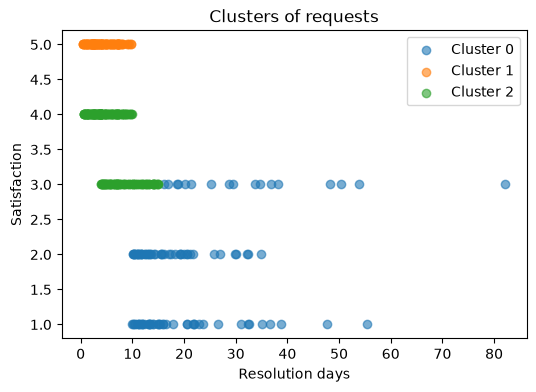

In [12]:
def kmeans(X, k=3, steps=25, seed=13):
    local_rng = np.random.default_rng(seed)
    centres = X[local_rng.choice(len(X), size=k, replace=False)].astype(float)
    labels = np.zeros(len(X), dtype=int)
    for _ in range(steps):
        dist = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        labels = dist.argmin(axis=1)
        for j in range(k):
            if np.any(labels == j):
                centres[j] = X[labels == j].mean(axis=0)
    return labels, centres


cluster_frame = requests[["resolution_days", "satisfaction_rating"]].to_numpy(dtype=float)
scaled = (cluster_frame - cluster_frame.mean(axis=0)) / cluster_frame.std(axis=0)
labels, _ = kmeans(scaled, k=3)
requests["cluster"] = labels

cluster_summary = (
    requests.groupby("cluster")
    .agg(
        count=("request_id", "count"),
        mean_days=("resolution_days", "mean"),
        mean_satisfaction=("satisfaction_rating", "mean"),
    )
    .round(2)
)
cluster_summary.to_csv(OUTPUTS / "cluster_summary.csv")
display(cluster_summary)

fig, ax = plt.subplots(figsize=(6, 4))
for label in sorted(requests["cluster"].unique()):
    part = requests[requests["cluster"] == label]
    ax.scatter(part["resolution_days"], part["satisfaction_rating"], alpha=0.6, label=f"Cluster {label}")
ax.set_xlabel("Resolution days")
ax.set_ylabel("Satisfaction")
ax.set_title("Clusters of requests")
ax.legend()
plt.show()


## Your written answer — cluster analysis

- Describe each cluster in one phrase (for example “slow and unhappy”).
- Which cluster should operations investigate first?

1. Describe each cluster in one phrase
  - Cluster 0: Slow resolution and very unhappy residents (20.67 days, satisfaction 1.75).
  - Cluster 1: Fast resolution and highly satisfied residents (4.18 days, satisfaction 5.00).
 - Cluster 2: Moderate resolution times and average satisfaction (5.97 days, satisfaction 3.63).

2. Which cluster should operations investigate first? - Cluster 0 should be investigated first.
It has the longest average resolution time of 20.67 days and the lowest satisfaction rating of 1.75. Operations should investigate the causes of these delays, identify service delivery weaknesses and prioritise improvements to restore resident satisfaction.


## 6. Time series analysis

A **time series** is a value tracked in order over time. Here we count how many requests were opened each week, and the weekly median resolution time.


,requests_opened,median_days
opened_on,,
2026-05-31,16,5.95
2026-06-07,18,6.00
2026-06-14,17,4.50
2026-06-21,12,6.30
2026-06-28,15,6.80


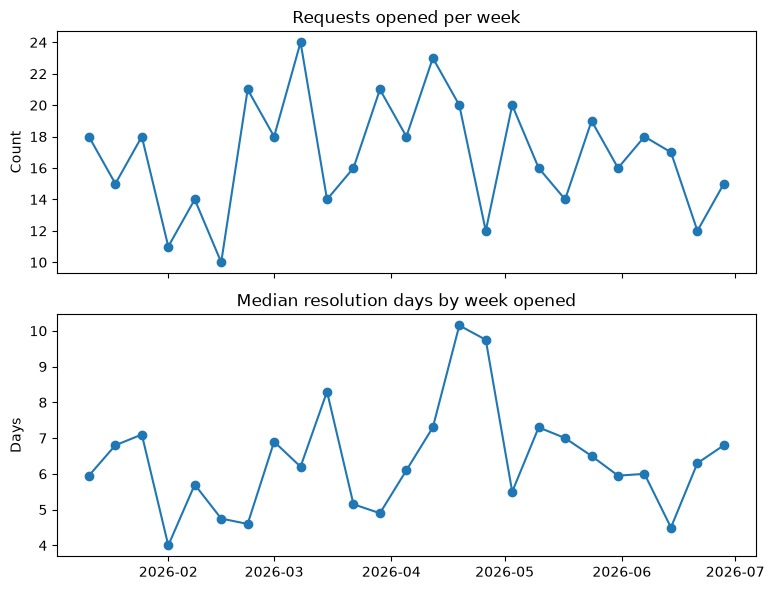

In [13]:
weekly = (
    requests.set_index("opened_on")
    .resample("W")
    .agg(requests_opened=("request_id", "count"), median_days=("resolution_days", "median"))
)
weekly.to_csv(OUTPUTS / "weekly_time_series.csv")
display(weekly.tail())

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(weekly.index, weekly["requests_opened"], marker="o")
axes[0].set_title("Requests opened per week")
axes[0].set_ylabel("Count")
axes[1].plot(weekly.index, weekly["median_days"], marker="o")
axes[1].set_title("Median resolution days by week opened")
axes[1].set_ylabel("Days")
plt.tight_layout()
plt.show()


## Your written answer — time series

- Do weekly volumes look steady, spiky, or trending?
- Is median resolution time moving with volume, or not?
- One risk of only looking at a single overall average:

1. Do weekly volumes look steady, spiky, or trending? - Weekly volumes look relatively steady, with some fluctuations. Requests increased from 16 to 18, then gradually fluctuated between 12 and 17 before reaching 15 in the final week.

2. Is median resolution time moving with volume, or not? - Not consistently. For example, requests increased from 16 to 18 between the first two weeks, while median resolution time changed only slightly from 5.95 to 6.00 days. This suggests that higher request volumes do not necessarily result in longer resolution times.

3. One risk of only looking at a single overall average: - Using only one overall average can hide weekly fluctuations, unusual delays and periods of poor performance. This may cause management to overlook operational problems that require attention.


## 7. Sentiment analysis

**Sentiment analysis** scores text as positive, negative or mixed.

This beginner version uses a small word list. It is not a language model. It is enough to see whether comments about slow jobs are more negative.


In [14]:
positive_words = {"thank", "thanks", "great", "happy", "quickly", "appreciate", "well", "fixed"}
negative_words = {"angry", "delay", "delayed", "poor", "slow", "terrible", "frustrating", "leaking", "wait"}


def sentiment_score(text):
    words = str(text).lower().replace(".", " ").replace(",", " ").split()
    pos = sum(word in positive_words for word in words)
    neg = sum(word in negative_words for word in words)
    return pos - neg


requests["sentiment_score"] = requests["resident_comment"].map(sentiment_score)
requests["sentiment_label"] = np.where(
    requests["sentiment_score"] > 0,
    "positive",
    np.where(requests["sentiment_score"] < 0, "negative", "neutral"),
)

print(requests["sentiment_label"].value_counts())
print()
print("Mean resolution days by sentiment")
display(
    requests.groupby("sentiment_label")["resolution_days"]
    .agg(count="count", mean="mean", median="median")
    .round(2)
)
requests[["request_id", "resolution_days", "sentiment_label", "resident_comment"]].head(8).to_csv(
    OUTPUTS / "sentiment_examples.csv",
    index=False,
)


sentiment_label
negative    172
positive    161
neutral      87
Name: count, dtype: int64

Mean resolution days by sentiment


,count,mean,median
sentiment_label,,,
negative,172,16.18,13.1
neutral,87,6.38,6.3
positive,161,3.21,2.7


## Your written answer — sentiment analysis

- Do negative comments have longer resolution times?
- Why can a small word list miss some comments?
- How could CityConnect use this alongside the numeric data?

1. Do negative comments have longer resolution times? - Yes. Negative comments have an average resolution time of 16.18 days, compared with 6.38 days for neutral comments and 3.21 days for positive comments. This suggests that longer resolution times are associated with lower resident satisfaction and more negative feedback.

2. Why can a small word list miss some comments? - A small word list can miss comments because residents use different words, slang, sarcasm, spelling mistakes and expressions to communicate their feelings. Some words can also have different meanings depending on the context.

3. How could CityConnect use this alongside the numeric data? - CityConnect could combine sentiment analysis with resolution times, service types and regions to identify departments with long delays and unhappy residents. Management could then prioritise problem areas, improve communication and take corrective action to improve service delivery.


In [15]:
summary = pd.DataFrame([{
    "mean_days": round(days.mean(), 2),
    "sd_days": round(days.std(), 2),
    "sd_residuals": round(requests["residual"].std(), 2),
    "range_days": round(days.max() - days.min(), 2),
    "iqr_days": round(days.quantile(0.75) - days.quantile(0.25), 2),
    "skewness": round(days.skew(), 2),
    "monte_carlo_p_over_14": round(prob_over_14, 3),
}])
summary.to_csv(OUTPUTS / "pa0301_0306_summary.csv", index=False)
print("Saved files in outputs:")
for path in sorted(OUTPUTS.glob("*.csv")):
    print("-", path.name)


Saved files in outputs:
- cluster_summary.csv
- cohort_by_opened_month.csv
- correlation_matrix.csv
- pa0301_0306_summary.csv
- regression_coefficients.csv
- sentiment_examples.csv
- weekly_time_series.csv


# Before you submit

1. Restart the kernel and run all cells from top to bottom.
2. Confirm the `outputs` folder contains the summary tables.
3. Put this notebook, the CSV, `outputs` and a README in a public GitHub repository.
4. Record a 5–10 minute Loom video. Cover PA0301–PA0305 briefly, then show at least regression, Monte Carlo, one grouping method (cohort or cluster), and sentiment.

## README checklist

- the business question
- mean, SD, residual SD, range, IQR and skewness
- what each PA0306 technique showed
- how to run the notebook
